# Inter-Area Oscillations and the PSS: RAMSES on the Kundur Two-Area System

This tutorial uses the [STEPSS](https://stepss.sps-lab.org) platform, through the
[stepss](https://stepss.sps-lab.org/python/) Python package, to reproduce the textbook
result this test system exists for: **a power system stabilizer (PSS) is what damps the
inter-area mode.**

We run the *same* disturbance twice, changing exactly one number in the data:

1. with the PSS gain at its design value (`dyn.dat`, $K_{STAB} = 20$), and
2. with the PSS switched off (`dyn_noPSS.dat`, $K_{STAB} = 0$),

then compare the rotor-angle swing between the two areas. In the first case the
oscillation decays; in the second it grows until the machines pull out of step and
RAMSES stops the run.

**Installation** (needed only if you are not on the course JupyterHub):

```bash
pip install jupyter ipython stepss
```

On Linux the engine additionally needs `libopenblas0 libgfortran5 libgomp1`
(see the [installation guide](https://stepss.sps-lab.org/python/installation/)).

## The two-area system

Kundur's two-area system (*Power System Stability and Control*, McGraw-Hill 1994,
Example 12.6) is the standard small benchmark for **inter-area oscillations**. It is
deliberately symmetric:

- **11 buses at 60 Hz.** Four 20-kV generator buses (1 to 4), stepped up to a 230-kV
  transmission ring (buses 5 to 11).
- **Four identical 900-MVA machines**, `G1` and `G2` in area 1, `G3` and `G4` in area 2,
  each with an `exc_kundur` AVR plus PSS and a `THERMAL_GENERIC1` governor.
- **Two load centres**, at bus 7 (967 MW) and bus 9 (1767 MW), each with a capacitor bank
  (200 and 350 Mvar) that props the local voltage up.
- **A weak tie**: buses 7 and 8 and buses 9 and 8 are joined by *double* circuits of
  fairly high impedance, so area 1 exports about 400 MW to area 2 across a long,
  electrically weak corridor.

That last point is the whole design. Two stiff areas joined by a weak tie oscillate
against each other at a low frequency, typically 0.2 to 0.8 Hz, with the machines of one
area swinging coherently against those of the other. High-gain AVRs, which every machine
here has ($K_A = 200$), make that mode *less* damped, and a PSS is the standard cure.

## The data files, and who reads what

| File | Contents |
|------|----------|
| `lf.dat` | Network **and** the solved operating point: 11 buses, 4 step-up transformers, 8 lines, 4 `GENER` records, the slack, and the `LFRESV` bus voltages |
| `dyn.dat` | Dynamic models: the four `SYNC_MACH` records with their `exc_kundur` AVR/PSS and `THERMAL_GENERIC1` governor, the two voltage-dependent loads (`vfd_load`), the two shunt capacitors |
| `dyn_noPSS.dat` | Identical to `dyn.dat`, with the PSS gain $K_{STAB}$ set from 20.0 to 0.0 on all four machines |
| `disturb.dst` | The disturbance: a +0.5 pu step on the active power of load `L9` at $t = 1$ s, 60 s horizon |
| `obs.dat` | Which variables to record (wildcards, so everything) |
| `solveroptions.dat` | Solver settings, plus the two monitoring controllers described below |

Note that `lf.dat` carries the `LFRESV` records itself, so this case needs no separate
power-flow step: unlike the Nordic system, the solved operating point travels with the
network file and RAMSES can initialise straight from it.

Two records at the bottom of `solveroptions.dat` matter later:

```
DCTL SIM_MINMAXVOLT Voltages 0.6 1.4 3 0 ;
DCTL SIM_MINMAXSPEED Speeds  0.9 1.05 2 0 ;
```

These are **watchdogs**, not physical models. They abort the simulation if any bus voltage
leaves [0.6, 1.4] pu or any machine speed leaves [0.9, 1.05] pu. In the unstable run below
this is what stops the integration, and the abort is the *result*, not a failure of the
tool.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import stepss

print('stepss', stepss.__version__)

stepss 3.70


In [2]:
# Plot style used throughout: recessive grid, no chart junk, fixed series colors.
plt.rcParams.update({
    'figure.figsize': (9, 4.2),
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linewidth': 0.6,
    'lines.linewidth': 1.8,
    'font.size': 11,
    'legend.frameon': False,
})

COL_PSS = '#2a78d6'     # blue:   PSS in service
COL_NOPSS = '#eb6834'   # orange: PSS disabled
COL_3 = '#1baf7a'       # aqua
COL_4 = '#eda100'       # yellow

## The disturbance

Small enough to stay in the linear regime, large enough to excite the mode:

In [3]:
print(open('disturb.dst').read())

  0.000 CONTINUE SOLVER BD 0.01 0.0001 0. ALL
  1.000 CHGPRM INJ L9 Po +0.5 0
 60.000 STOP



`CHGPRM INJ L9 Po +0.5 0` raises the active-power set-point of the load at bus 9, in the
importing area, by 0.5 pu on the injector base. Area 1 must ship the extra power across
the weak tie, which is exactly the path the inter-area mode lives on.

## Part 1: the base case, PSS in service

A RAMSES case is a `cfg` object listing the input files and where the outputs go.

In [4]:
# clear outputs of any previous run
for f in glob.glob('*.trj') + glob.glob('*.trace'):
    os.remove(f)


def run_case(dyn_file, tag):
    """Run the load step with the given dynamic data file.

    Returns (extractor, completed) where `completed` is False when a monitoring
    DCTL aborted the integration before the STOP event of the scenario.
    """
    case = stepss.cfg()
    case.addData('lf.dat')             # network + solved operating point
    case.addData(dyn_file)             # dynamic models
    case.addData('solveroptions.dat')  # solver settings + monitoring DCTLs
    case.addDst('disturb.dst')         # +0.5 pu step on L9 at t = 1 s
    case.addObs('obs.dat')
    case.addTrj(f'output_{tag}.trj')
    case.addOut(f'output_{tag}.trace')
    case.addInit(f'init_{tag}.trace')

    completed = True
    try:
        stepss.sim().execSim(case)
    except Exception as err:
        completed = False
        print(f'[{tag}] integration stopped early: {str(err).split("Last message was:")[-1].strip()}')
    return stepss.extractor(case.getTrj()), completed


ext_pss, done_pss = run_case('dyn.dat', 'pss')
print('PSS case completed:', done_pss)

PSS case completed: True


### Reading rotor angles in this case

`solveroptions.dat` sets `$OMEGA_REF SYN`, so rotor angles are measured against a frame
turning at *constant nominal speed*, not against the centre of inertia. After the load
step the governors settle the system slightly below 60 Hz, so **every** machine angle then
drifts downwards together at the same rate. That common drift is not an oscillation:

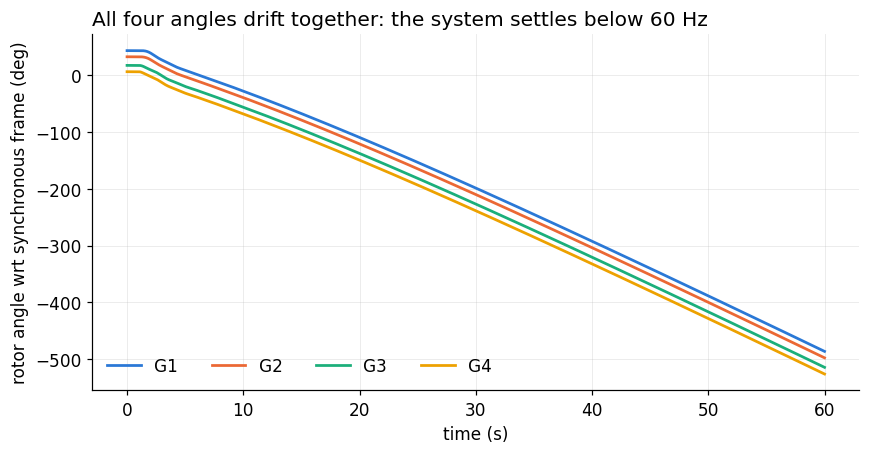

settled machine speed: 0.99955 pu  ->  59.973 Hz


In [5]:
t = ext_pss.getSync('G1').A.time
ang = {g: ext_pss.getSync(g).A.value for g in ['G1', 'G2', 'G3', 'G4']}

fig, ax = plt.subplots()
for g, colr in zip(['G1', 'G2', 'G3', 'G4'], [COL_PSS, COL_NOPSS, COL_3, COL_4]):
    ax.plot(t, ang[g], color=colr, label=g)
ax.set_xlabel('time (s)')
ax.set_ylabel('rotor angle wrt synchronous frame (deg)')
ax.set_title('All four angles drift together: the system settles below 60 Hz', loc='left')
ax.legend(loc='lower left', ncols=4)
plt.show()

f_settle = 60.0 * ext_pss.getSync('G1').S.value[-1]
print(f'settled machine speed: {ext_pss.getSync("G1").S.value[-1]:.5f} pu  ->  {f_settle:.3f} Hz')

The information is in the **differences**. The inter-area mode is the swing of area 1
against area 2, so we take the angle of a machine in each area and subtract:

$$\delta_{\text{inter-area}} = \delta_{G1} - \delta_{G3}$$

The common drift cancels exactly, leaving the oscillation.

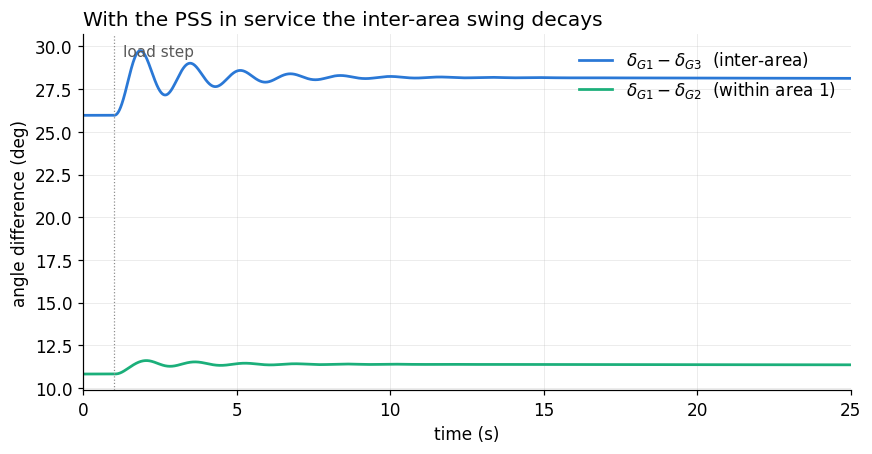

In [6]:
d_pss = ang['G1'] - ang['G3']
d_local = ang['G1'] - ang['G2']

fig, ax = plt.subplots()
ax.plot(t, d_pss, color=COL_PSS, label=r'$\delta_{G1}-\delta_{G3}$  (inter-area)')
ax.plot(t, d_local, color=COL_3, label=r'$\delta_{G1}-\delta_{G2}$  (within area 1)')
ax.axvline(1.0, color='0.55', linewidth=0.8, linestyle=':')
ax.annotate('load step', (1.0, ax.get_ylim()[1]), xytext=(6, -14),
            textcoords='offset points', color='0.35', fontsize=10)
ax.set_xlabel('time (s)')
ax.set_ylabel('angle difference (deg)')
ax.set_title('With the PSS in service the inter-area swing decays', loc='left')
ax.set_xlim(0, 25)
ax.legend(loc='upper right')
plt.show()

Two modes are visible and they are not the same. The **local** mode, one machine against
its neighbour in the same area, is fast and dies almost immediately. The **inter-area**
mode is slower and lives much longer, and it is the one the PSS is tuned for.

We can read its frequency and damping straight off the decaying envelope, by fitting a
straight line to the logarithm of the successive peak amplitudes:

In [7]:
def mode_estimate(time, signal, t_from=1.5, t_to=25.0):
    """Frequency and damping ratio of the dominant mode, from successive peaks."""
    m = (time >= t_from) & (time <= t_to)
    tt, xx = time[m], signal[m] - signal[m][-1]
    # local maxima of the deviation from the settling value
    peaks = [i for i in range(1, len(xx) - 1) if xx[i] > xx[i - 1] and xx[i] >= xx[i + 1] and xx[i] > 0]
    if len(peaks) < 3:
        return None
    tp, xp = tt[peaks], xx[peaks]
    period = np.mean(np.diff(tp))
    # logarithmic decrement over the peak train
    slope = np.polyfit(tp, np.log(xp), 1)[0]
    sigma = -slope
    omega_d = 2 * np.pi / period
    zeta = sigma / np.hypot(sigma, omega_d)
    return dict(f_hz=1.0 / period, zeta=zeta, n_peaks=len(peaks))


est = mode_estimate(t, d_pss)
print(f"inter-area mode with PSS: {est['f_hz']:.3f} Hz, "
      f"damping ratio {est['zeta'] * 100:.1f} % (from {est['n_peaks']} peaks)")

inter-area mode with PSS: 0.627 Hz, damping ratio 6.1 % (from 12 peaks)


Around 0.6 Hz, in the middle of the 0.2 to 0.8 Hz band inter-area modes occupy, and damped
at roughly 6 %. Grid codes commonly ask for at least 3 to 5 % on such a mode, so the tuned
PSS puts this system just the right side of the line. Note this is an estimate read off a
decaying time response, and a mode that close to the threshold is exactly the case where
you would want the eigenvalue computation suggested at the end instead.

## Part 2: the same disturbance with the PSS disabled

`dyn_noPSS.dat` differs from `dyn.dat` in four numbers, one per machine: the PSS gain
$K_{STAB}$ in the `exc_kundur` record, 20.0 becomes 0.0. Everything else, including the
AVR gain of 200, is untouched.

In [8]:
import difflib
diff = difflib.unified_diff(open('dyn.dat').readlines(), open('dyn_noPSS.dat').readlines(),
                            'dyn.dat', 'dyn_noPSS.dat', n=0)
for line in diff:
    if line.startswith(('---', '+++')) or (line[:1] in '-+' and line[1:].strip()):
        print(line.rstrip())

--- dyn.dat
+++ dyn_noPSS.dat
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4
-              EXC exc_kundur   0.01  200   1.0   1.0   20.0   10.0  0.05  0.02  3.0  5.4
+              EXC exc_kundur   0.01  200   1.0   1.0    0.0   10.0  0.05  0.02  3.0  5.4


In [9]:
ext_nopss, done_nopss = run_case('dyn_noPSS.dat', 'nopss')
print('no-PSS case completed:', done_nopss)

[nopss] integration stopped early: ERROR CALL FROM DCTL sim_minmaxvolt Voltages t =   36.5002         Voltage out of bounds at bus 8 :  0.60
no-PSS case completed: False


The run did **not** reach the 60-s `STOP` of the scenario. The `SIM_MINMAXVOLT` watchdog
fired: a bus voltage fell through 0.6 pu, which is what happens when machines lose
synchronism and the voltage collapses at the electrical centre of the swing. RAMSES stops
there rather than integrating a meaningless post-pole-slip trajectory, and everything
recorded up to that instant is still in the trajectory file.

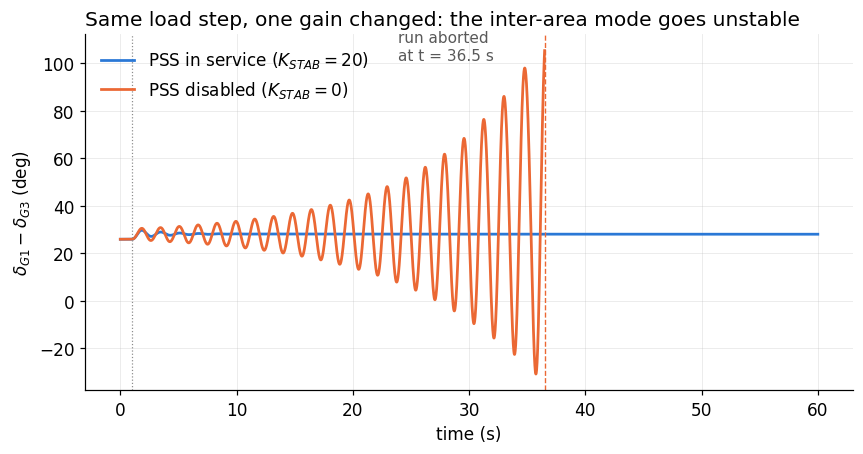

angle difference span, PSS      :    3.8 deg
angle difference span, no PSS   :  136.1 deg
final angle difference, no PSS  :  105.4 deg  (started at 26.0 deg)


In [10]:
t_np = ext_nopss.getSync('G1').A.time
d_nopss = ext_nopss.getSync('G1').A.value - ext_nopss.getSync('G3').A.value

fig, ax = plt.subplots()
ax.plot(t, d_pss, color=COL_PSS, label='PSS in service ($K_{STAB}=20$)')
ax.plot(t_np, d_nopss, color=COL_NOPSS, label='PSS disabled ($K_{STAB}=0$)')
ax.axvline(1.0, color='0.55', linewidth=0.8, linestyle=':')
ax.axvline(t_np[-1], color=COL_NOPSS, linewidth=0.9, linestyle='--')
ax.annotate(f'run aborted\nat t = {t_np[-1]:.1f} s', (t_np[-1], d_nopss.max()),
            xytext=(-96, -6), textcoords='offset points', color='0.35', fontsize=10)
ax.set_xlabel('time (s)')
ax.set_ylabel(r'$\delta_{G1}-\delta_{G3}$ (deg)')
ax.set_title('Same load step, one gain changed: the inter-area mode goes unstable', loc='left')
ax.legend(loc='upper left')
plt.show()

print(f'angle difference span, PSS      : {d_pss.max() - d_pss.min():6.1f} deg')
print(f'angle difference span, no PSS   : {d_nopss.max() - d_nopss.min():6.1f} deg')
print(f'final angle difference, no PSS  : {d_nopss[-1]:6.1f} deg  (started at {d_nopss[0]:.1f} deg)')

The contrast is the whole point of the test system. The same 0.5 pu load step, on the same
network, at the same operating point: with the PSS the swing peaks at a few degrees and is
gone within 20 s; without it the swing grows monotonically until the two areas are more
than 100 degrees apart and the run is stopped.

Watch the same instability in the two other quantities an operator would see, the machine
speeds and the tie-corridor voltage:

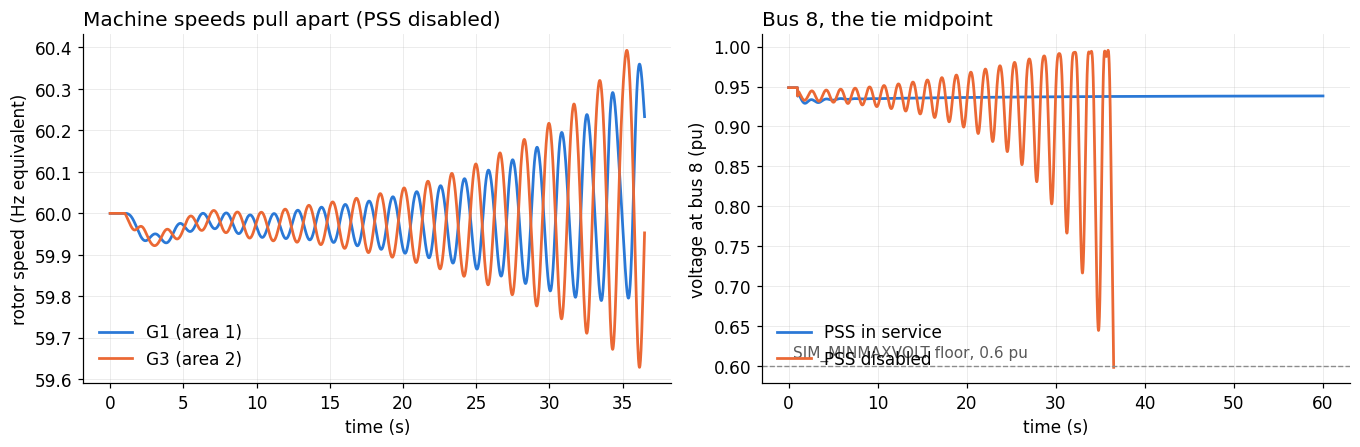

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
for g, colr, lbl in [('G1', COL_PSS, 'G1 (area 1)'), ('G3', COL_NOPSS, 'G3 (area 2)')]:
    s = ext_nopss.getSync(g).S
    ax.plot(s.time, 60.0 * s.value, color=colr, label=lbl)
ax.set_xlabel('time (s)')
ax.set_ylabel('rotor speed (Hz equivalent)')
ax.set_title('Machine speeds pull apart (PSS disabled)', loc='left')
ax.legend(loc='lower left')

ax = axes[1]
for ext, colr, lbl in [(ext_pss, COL_PSS, 'PSS in service'), (ext_nopss, COL_NOPSS, 'PSS disabled')]:
    v = ext.getBus('8').mag
    ax.plot(v.time, v.value, color=colr, label=lbl)
ax.axhline(0.6, color='0.55', linewidth=0.9, linestyle='--')
ax.annotate('SIM_MINMAXVOLT floor, 0.6 pu', (0.5, 0.6), xytext=(0, 6),
            textcoords='offset points', color='0.35', fontsize=10)
ax.set_xlabel('time (s)')
ax.set_ylabel('voltage at bus 8 (pu)')
ax.set_title('Bus 8, the tie midpoint', loc='left')
ax.legend(loc='lower left')

plt.tight_layout()
plt.show()

Bus 8 is the electrical midpoint of the tie, and it is the bus that collapses: as the two
areas separate in angle, the voltage at the point between them is squeezed towards zero.
That is why the watchdog placed the floor there rather than at a generator terminal.

In [12]:
# Key outcomes, side by side.
print(f'{"":34}{"PSS":>12} {"no PSS":>12}')
rows = [
    ('simulated to (s)',        lambda e: e.getSync('G1').A.time[-1]),
    ('swing span, delta G1-G3 (deg)', lambda e: np.ptp(e.getSync('G1').A.value - e.getSync('G3').A.value)),
    ('final delta G1-G3 (deg)',  lambda e: (e.getSync('G1').A.value - e.getSync('G3').A.value)[-1]),
    ('lowest V at bus 8 (pu)',   lambda e: e.getBus('8').mag.value.min()),
    ('lowest machine speed (pu)', lambda e: min(e.getSync(g).S.value.min() for g in ['G1', 'G2', 'G3', 'G4'])),
]
for label, fn in rows:
    print(f'{label:34}{fn(ext_pss):12.3f} {fn(ext_nopss):12.3f}')

                                           PSS       no PSS
simulated to (s)                        60.000       36.500
swing span, delta G1-G3 (deg)            3.788      136.129
final delta G1-G3 (deg)                 28.087      105.369
lowest V at bus 8 (pu)                   0.929        0.599
lowest machine speed (pu)                0.999        0.994


## What you have seen

- A RAMSES case assembled from four files and run twice, with **one parameter changed**
  between the runs, which is the cleanest way to attribute an effect to a control.
- The **inter-area mode** of the two-area system, near 0.5 Hz, separated from the faster
  local mode by taking angle differences across the areas rather than absolute angles.
- The PSS doing its job: with $K_{STAB} = 20$ the mode is damped; with $K_{STAB} = 0$ the
  same disturbance drives it unstable and the machines pull out of step.
- A **monitoring DCTL stopping a run on purpose**. `SIM_MINMAXVOLT` firing is a result to
  report, not an error to work around, and the trajectory written up to that point is
  complete and usable.

### Things to try

- **Find the stability boundary.** Copy `dyn_noPSS.dat` and sweep $K_{STAB}$ (say 0, 2, 5,
  10, 20) on all four machines, re-running each time and recording the damping ratio from
  `mode_estimate`. At what gain does the mode cross into the left half-plane?
- **Ask small-signal analysis directly.** Rather than inferring damping from a time
  response, the `EIG` disturbance makes RAMSES compute the eigenvalues of the linearised
  system, giving the inter-area mode's frequency and damping exactly. See the
  [small-signal stability guide](https://stepss.sps-lab.org/user-guide/small-signal/).
- **Change what excites the mode.** Replace the load step with a line trip
  (`BREAKER BRANCH 7-8#1 0 0`) to remove one of the two tie circuits, weakening the
  corridor and moving the mode.
- **Look at the PSS acting.** `ext_pss.getExc('G1')` exposes the exciter states, so you can
  plot the stabilizer's contribution to the field voltage against the speed deviation it
  is derived from.

### References

- P. Kundur, *Power System Stability and Control*, McGraw-Hill, 1994, Example 12.6.
- stepss documentation: <https://stepss.sps-lab.org/python/>
- STEPSS user guide: <https://stepss.sps-lab.org/user-guide/>, and the
  [`exc_kundur` model](https://stepss.sps-lab.org/models/custom-exciters/)